# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# TODO 1: voxel count and storage at 16 bits per voxel
nx_new, ny_new, nz_new = 512, 512, 300

n_voxels = nx_new * ny_new * nz_new
scan_mb = n_voxels * 2 / (1024 ** 2)

# TODO 2: physical extent and voxel volume
spacing_new = (0.5, 0.5, 1.0)  # (x, y, z), in mm

extent_mm = (
    nx_new * spacing_new[0],
    ny_new * spacing_new[1],
    nz_new * spacing_new[2]
)
voxel_mm3 = np.prod(spacing_new)

# TODO 3: samples per frame and 120-frame video
samples_per_frame = nx_new * nz_new * ny_new
samples_video = samples_per_frame * 120

# TODO 4: early ray termination saves 35% of samples
samples_video_ert = samples_video * (1 - 0.35)

print(
    f"{n_voxels:,} voxels = {scan_mb:.1f} MB | "
    f"extent {extent_mm} mm | voxel {voxel_mm3} mm^3"
)
print(
    f"samples/frame {samples_per_frame:,} | "
    f"120 frames {samples_video:,} | "
    f"with early termination {samples_video_ert:,.0f}"
)

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 6,134,169,600


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
Ignoring anisotropic voxel spacing would distort the anatomy in coronal and sagittal views because the physical distance represented by a voxel differs between the axes. Structures could appear stretched or compressed, leading to incorrect visual judgments about their size and shape. Measurements and spatial relationships could also become misleading if the software treated all voxels as equal-sized cubes instead of applying the correct aspect ratio.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x): (28, 40, 41)


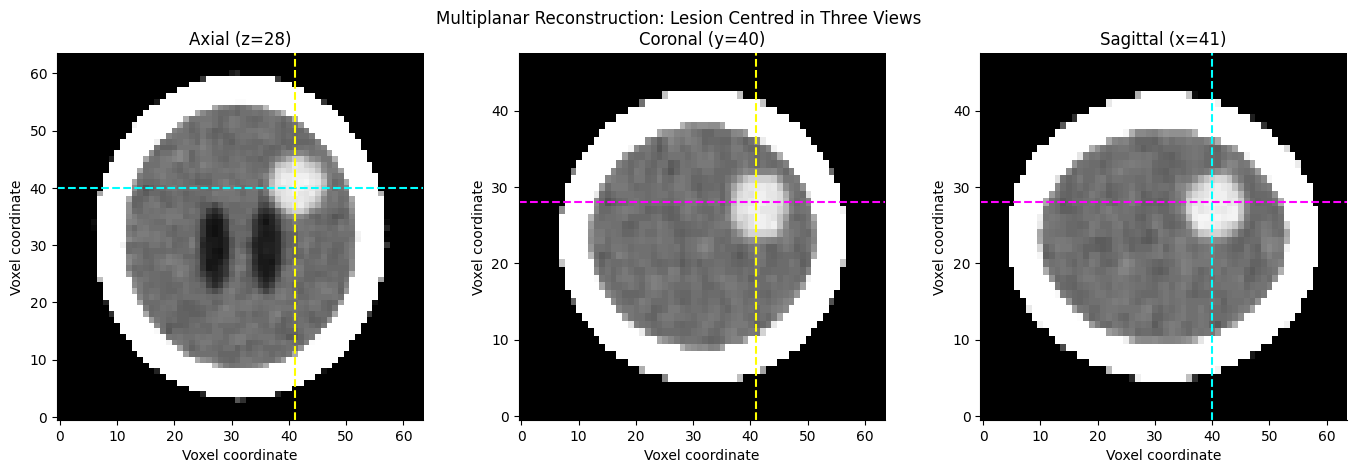

Ground-truth centroid (z, y, x): [27.5 40.5 41.5]
Centroid distance from ground truth: 2.92 mm


In [4]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: identify candidate voxels without using labels
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)

candidates = inside & (vol > 55) & (vol < 90)

# TODO 2: largest connected component and its centroid
components, n_components = ndimage.label(candidates)

if n_components == 0:
    raise ValueError("No lesion candidates found. Check the HU range and inside mask.")

component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0
largest_component = component_sizes.argmax()

lesion = components == largest_component
cz, cy, cx = np.round(
    ndimage.center_of_mass(lesion)
).astype(int)

print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")

# TODO 3: axial, coronal, sagittal MPR with cross-hairs
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

axes[0].imshow(
    window(vol[cz], 80, 40),
    cmap="gray", origin="lower", vmin=0, vmax=1
)
axes[0].axhline(cy, color="cyan", linestyle="--")
axes[0].axvline(cx, color="yellow", linestyle="--")
axes[0].set_title(f"Axial (z={cz})")

axes[1].imshow(
    window(vol[:, cy, :], 80, 40),
    cmap="gray", origin="lower", aspect=ASPECT,
    vmin=0, vmax=1
)
axes[1].axhline(cz, color="magenta", linestyle="--")
axes[1].axvline(cx, color="yellow", linestyle="--")
axes[1].set_title(f"Coronal (y={cy})")

axes[2].imshow(
    window(vol[:, :, cx], 80, 40),
    cmap="gray", origin="lower", aspect=ASPECT,
    vmin=0, vmax=1
)
axes[2].axhline(cz, color="magenta", linestyle="--")
axes[2].axvline(cy, color="cyan", linestyle="--")
axes[2].set_title(f"Sagittal (x={cx})")

for ax in axes:
    ax.set_xlabel("Voxel coordinate")
    ax.set_ylabel("Voxel coordinate")

plt.suptitle("Multiplanar Reconstruction: Lesion Centred in Three Views")
plt.tight_layout()
plt.show()

# TODO 4: evaluation only — compare with the ground-truth centroid
truth_centroid = np.argwhere(labels == 5).mean(axis=0)
estimated_centroid = np.array([cz, cy, cx])

distance_mm = np.linalg.norm(
    (estimated_centroid - truth_centroid) * np.array(SPACING)
)

print(f"Ground-truth centroid (z, y, x): {truth_centroid}")
print(f"Centroid distance from ground truth: {distance_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
Erosion removes a thin layer from the inside-brain mask so that voxels close to the skull and tissue boundaries are less likely to be included. Because of the partial-volume effect, one voxel can contain a mixture of tissues and have an intensity between their typical values. The intensity ranges of brain tissue and tumour can therefore overlap, making a transfer function based only on intensity imperfect. Erosion reduces some boundary contamination, although it cannot completely resolve overlapping intensity ranges.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


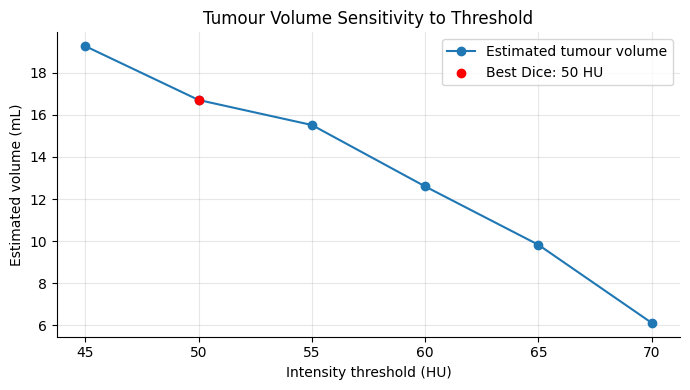

Estimated tumour volume range: 6.12–19.26 mL
Best Dice threshold: 50 HU (volume 16.70 mL)


In [5]:
truth = labels == 5
rows = []

# TODO 1 & 2: connected component containing the estimated lesion centre
for c in [45, 50, 55, 60, 65, 70]:
    components, _ = ndimage.label(vol > c)

    seed_label = components[cz, cy, cx]
    region = components == seed_label if seed_label != 0 else np.zeros_like(
        vol, dtype=bool
    )

    voxel_count = int(region.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000

    # Evaluation only
    dice = (
        2 * (region & truth).sum() / (region.sum() + truth.sum())
        if region.sum() + truth.sum() > 0
        else 0
    )

    rows.append({
        "threshold_hu": c,
        "voxels": voxel_count,
        "volume_ml": volume_ml,
        "dice_vs_truth": dice
    })

table = pd.DataFrame(rows)
display(table.round(3))

# TODO 3: plot volume vs threshold and mark best Dice
best_index = table["dice_vs_truth"].idxmax()
best_threshold = table.loc[best_index, "threshold_hu"]
best_volume = table.loc[best_index, "volume_ml"]

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    table["threshold_hu"],
    table["volume_ml"],
    marker="o",
    label="Estimated tumour volume"
)
ax.scatter(
    best_threshold,
    best_volume,
    color="red",
    zorder=3,
    label=f"Best Dice: {best_threshold} HU"
)

ax.set_xlabel("Intensity threshold (HU)")
ax.set_ylabel("Estimated volume (mL)")
ax.set_title("Tumour Volume Sensitivity to Threshold")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: report volume range
volume_min = table["volume_ml"].min()
volume_max = table["volume_ml"].max()

print(
    f"Estimated tumour volume range: "
    f"{volume_min:.2f}–{volume_max:.2f} mL"
)
print(
    f"Best Dice threshold: {best_threshold} HU "
    f"(volume {best_volume:.2f} mL)"
)

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
In a real clinical setting, I would select the threshold using radiologist-reviewed images and the tumour's expected appearance, then check whether the segmentation is anatomically plausible across all three planes. I would compare several reasonable thresholds and report the resulting volume range instead of presenting one value as exact. A sensitivity plot and side-by-side segmentation overlays would show how the boundary changes as the threshold changes. The final value and uncertainty range should be reviewed by the radiologist and neurosurgeon before clinical use.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

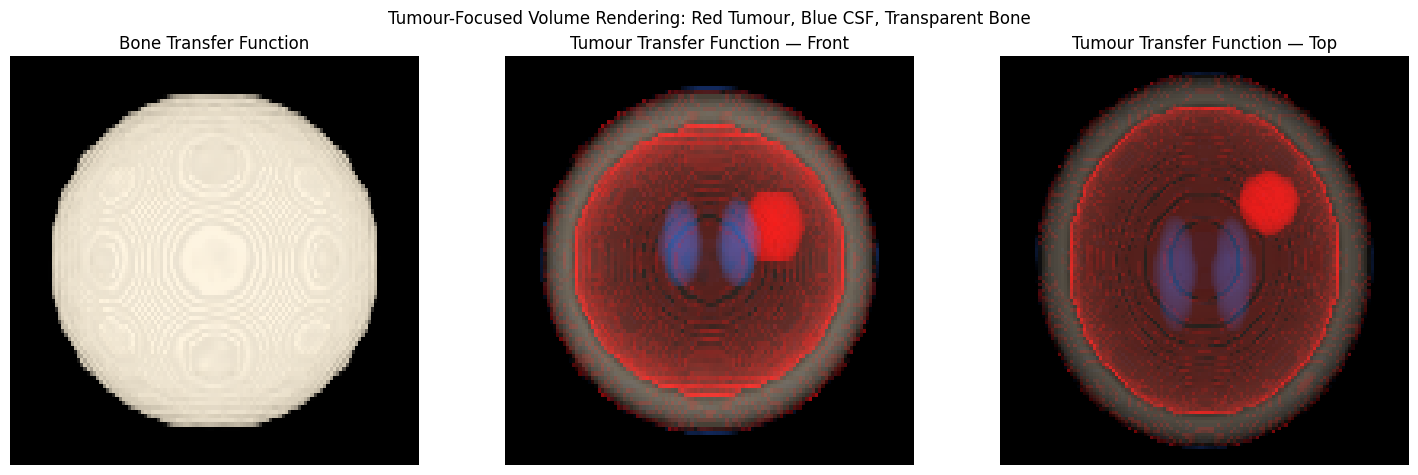

In [6]:
bone_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (200, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.3),
    (1500, (1, 1, 1), 0.6)
])

# TODO 2: custom transfer function
# Air and soft tissue transparent; bone almost transparent;
# CSF blue and faint; tumour red.
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (-200, (0, 0, 0), 0.0),

    # Soft tissue remains transparent
    (0, (0, 0, 0), 0.0),

    # CSF: faint blue
    (5, (0.2, 0.45, 1.0), 0.025),
    (20, (0.2, 0.45, 1.0), 0.025),

    # Brain tissue transparent
    (28, (0, 0, 0), 0.0),
    (50, (0, 0, 0), 0.0),

    # Tumour: red
    (55, (1.0, 0.05, 0.05), 0.12),
    (80, (1.0, 0.05, 0.05), 0.12),
    (95, (0, 0, 0), 0.0),

    # Bone: nearly transparent for anatomical context
    (200, (1.0, 0.9, 0.75), 0.005),
    (400, (1.0, 0.9, 0.75), 0.01),
    (1500, (1.0, 1.0, 1.0), 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1: bone-only front render
bone_image, bone_alpha = render(vol, bone_tf, axis=1)
axes[0].imshow(
    np.clip(bone_image, 0, 1),
    origin="lower",
    aspect=ASPECT
)
axes[0].set_title("Bone Transfer Function")

# TODO 3: tumour transfer function, front view
front_image, front_alpha = render(vol, tumour_tf, axis=1)
axes[1].imshow(
    np.clip(front_image, 0, 1),
    origin="lower",
    aspect=ASPECT
)
axes[1].set_title("Tumour Transfer Function — Front")

# Tumour transfer function, top view
top_image, top_alpha = render(vol, tumour_tf, axis=0)
axes[2].imshow(
    np.clip(top_image, 0, 1),
    origin="lower"
)
axes[2].set_title("Tumour Transfer Function — Top")

for ax in axes:
    ax.axis("off")

# TODO 4: conclusion-style title
plt.suptitle(
    "Tumour-Focused Volume Rendering: Red Tumour, Blue CSF, Transparent Bone"
)
plt.tight_layout()
plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
The faint red rim is caused by occlusion and overlapping intensity ranges: partial-volume voxels near the skull or brain boundary can fall within the tumour's selected intensity range and be coloured red. A segmentation or threshold-based isosurface can help remove the rim by restricting the displayed tumour to a connected region around the estimated lesion centre. A transfer function alone cannot reliably distinguish two tissues that have overlapping intensities, because it assigns colour and opacity based on intensity rather than anatomical identity or connectivity.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
The estimated lesion is centred near voxel coordinates (z = 28, y = 40, x = 41), corresponding to a location in the central-to-lower portion of the supplied head volume. Depending on the selected intensity threshold, the estimated tumour volume ranges from approximately 6.12 to 19.26 mL, demonstrating that the measurement is sensitive to the segmentation threshold. I recommend opening the tumour-board meeting with the three-plane multiplanar reconstruction (MPR), because slicing exposes internal anatomy and lets the team inspect the lesion in axial, coronal and sagittal views without the occlusion that affects a 3-D render. The transfer-function render can then provide context by showing the tumour in red and CSF in blue while keeping bone nearly transparent. The board should remember that overlapping tissue intensities and partial-volume effects can create misleading boundaries, so the 3-D rendering is a visualization aid rather than definitive proof of tumour extent.